In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv("./data/bitcoin_price_Training - Training.csv")
df.head()

,Date,Open,High,Low,Close,Volume,Market Cap
0,"Jul 31, 2017",2763.24,2889.62,2720.61,2875.34,"860,575,000","45,535,800,000"
1,"Jul 30, 2017",2724.39,2758.53,2644.85,2757.18,"705,943,000","44,890,700,000"
2,"Jul 29, 2017",2807.02,2808.76,2692.80,2726.45,"803,746,000","46,246,700,000"
3,"Jul 28, 2017",2679.73,2897.45,2679.73,2809.01,"1,380,100,000","44,144,400,000"
4,"Jul 27, 2017",2538.71,2693.32,2529.34,2671.78,"789,104,000","41,816,500,000"


In [3]:
df.describe()

,Open,High,Low,Close
count,1556.000000,1556.000000,1556.000000,1556.000000
mean,582.625328,597.992847,567.851446,584.239396
std,523.137312,542.992855,505.877401,525.904442
min,68.500000,74.560000,65.530000,68.430000
25%,254.287500,260.327500,248.835000,254.320000
50%,438.600000,447.560000,430.570000,438.855000
75%,662.437500,674.525000,646.735000,663.402500
max,2953.220000,2999.910000,2840.530000,2958.110000


In [4]:
df.dtypes

Date              str
Open          float64
High          float64
Low           float64
Close         float64
Volume            str
Market Cap        str
dtype: object

In [5]:
df['Date']= pd.to_datetime(df['Date'])
df.dtypes

Date          datetime64[us]
Open                 float64
High                 float64
Low                  float64
Close                float64
Volume                   str
Market Cap               str
dtype: object

In [6]:
df['Date'].dtypes

dtype('<M8[us]')

In [7]:
df=df.sort_index()
df

,Date,Open,High,Low,Close,Volume,Market Cap
0,2017-07-31,2763.24,2889.62,2720.61,2875.34,"860,575,000","45,535,800,000"
1,2017-07-30,2724.39,2758.53,2644.85,2757.18,"705,943,000","44,890,700,000"
2,2017-07-29,2807.02,2808.76,2692.80,2726.45,"803,746,000","46,246,700,000"
3,2017-07-28,2679.73,2897.45,2679.73,2809.01,"1,380,100,000","44,144,400,000"
4,2017-07-27,2538.71,2693.32,2529.34,2671.78,"789,104,000","41,816,500,000"
...,...,...,...,...,...,...,...
1551,2013-05-02,116.38,125.60,92.28,105.21,-,"1,292,190,000"
1552,2013-05-01,139.00,139.89,107.72,116.99,-,"1,542,820,000"
1553,2013-04-30,144.00,146.93,134.05,139.00,-,"1,597,780,000"
1554,2013-04-29,134.44,147.49,134.00,144.54,-,"1,491,160,000"


In [8]:
df.set_index('Date', inplace=True)
df.head()

,Open,High,Low,Close,Volume,Market Cap
Date,,,,,,
2017-07-31,2763.24,2889.62,2720.61,2875.34,"860,575,000","45,535,800,000"
2017-07-30,2724.39,2758.53,2644.85,2757.18,"705,943,000","44,890,700,000"
2017-07-29,2807.02,2808.76,2692.80,2726.45,"803,746,000","46,246,700,000"
2017-07-28,2679.73,2897.45,2679.73,2809.01,"1,380,100,000","44,144,400,000"
2017-07-27,2538.71,2693.32,2529.34,2671.78,"789,104,000","41,816,500,000"


In [9]:
data = df.copy()

Text(0, 0.5, 'Daily Bitcoin Price')

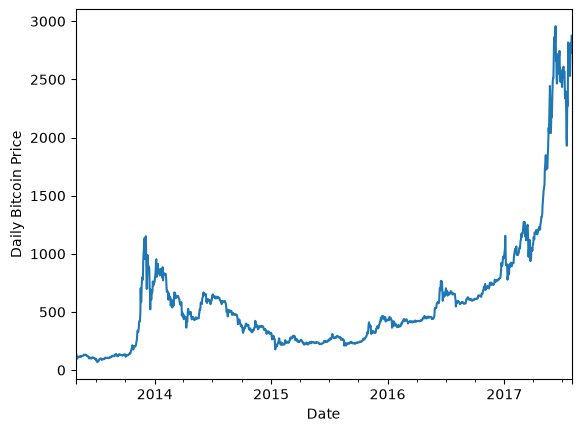

In [10]:
data['Close'].plot()
plt.ylabel('Daily Bitcoin Price')

In [11]:
data2 = data['Close']
data2.head()

Date
2017-07-31    2875.34
2017-07-30    2757.18
2017-07-29    2726.45
2017-07-28    2809.01
2017-07-27    2671.78
Name: Close, dtype: float64

In [12]:
# resampling on week basis and then sum
data2.resample('W').sum() # this will give the sum of all days in a week

Date
2013-04-28      134.21
2013-05-05      831.90
2013-05-12      797.48
2013-05-19      830.97
2013-05-26      894.13
                ...   
2017-07-09    17984.69
2017-07-16    15629.11
2017-07-23    17846.60
2017-07-30    18825.21
2017-08-06     2875.34
Freq: W-SUN, Name: Close, Length: 224, dtype: float64

<Axes: xlabel='Date'>

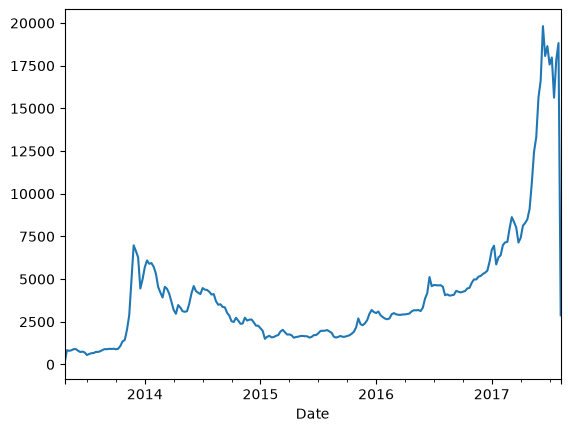

In [13]:
data2.resample('W').sum().plot() # plotting the weekly sum of bitcoin price

<Axes: xlabel='Date'>

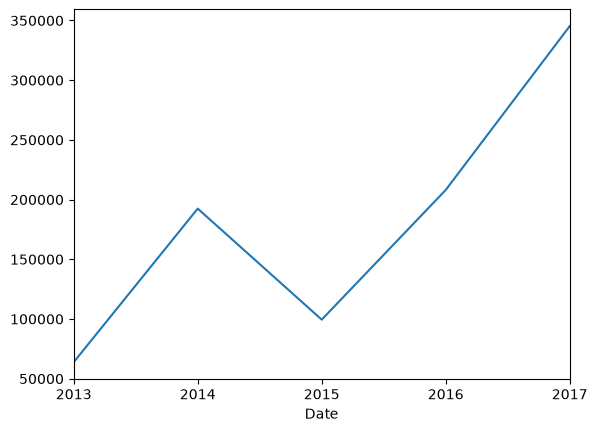

In [14]:
# on yearly basis
data2.resample('YE').sum().plot() # plotting the yearly sum of bitcoin price

<Axes: xlabel='Date'>

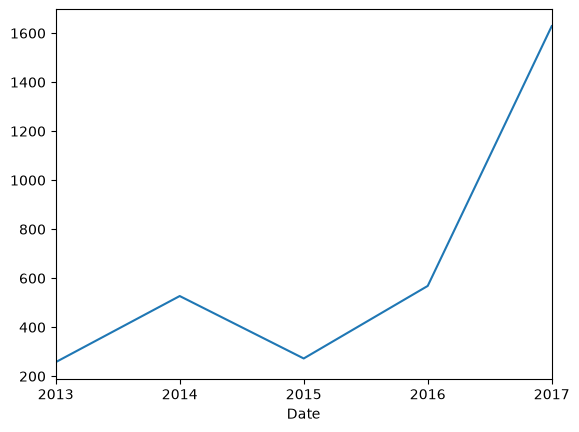

In [15]:
data2.resample('YE').mean().plot() # plotting the yearly mean of bitcoin price

In [16]:
data2.index

DatetimeIndex(['2017-07-31', '2017-07-30', '2017-07-29', '2017-07-28',
               '2017-07-27', '2017-07-26', '2017-07-25', '2017-07-24',
               '2017-07-23', '2017-07-22',
               ...
               '2013-05-07', '2013-05-06', '2013-05-05', '2013-05-04',
               '2013-05-03', '2013-05-02', '2013-05-01', '2013-04-30',
               '2013-04-29', '2013-04-28'],
              dtype='datetime64[us]', name='Date', length=1556, freq=None)

In [17]:
data2.index.dayofweek

Index([0, 6, 5, 4, 3, 2, 1, 0, 6, 5,
       ...
       1, 0, 6, 5, 4, 3, 2, 1, 0, 6],
      dtype='int32', name='Date', length=1556)

In [18]:
weekday = data.groupby(data2.index.dayofweek)['Close'].mean()
weekday

Date
0    588.738655
1    582.402658
2    581.731216
3    585.565135
4    583.876622
5    584.545180
6    582.802511
Name: Close, dtype: float64

In [19]:
weekday.index=['Mon','Tue','Wed','Thu','Fri','Sat','Sun']
weekday

Mon    588.738655
Tue    582.402658
Wed    581.731216
Thu    585.565135
Fri    583.876622
Sat    584.545180
Sun    582.802511
Name: Close, dtype: float64

<Axes: >

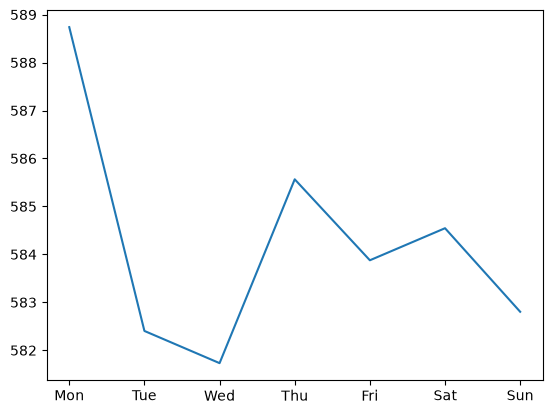

In [20]:
weekday.plot()

In [21]:
days = data2.index.dayofyear
days

Index([212, 211, 210, 209, 208, 207, 206, 205, 204, 203,
       ...
       127, 126, 125, 124, 123, 122, 121, 120, 119, 118],
      dtype='int32', name='Date', length=1556)

In [22]:
data.groupby(days)['Close'].mean()

Date
1      629.5775
2      643.1525
3      643.4125
4      677.8800
5      663.3350
         ...   
362    600.1375
363    616.6550
364    616.7475
365    616.5025
366    963.7400
Name: Close, Length: 366, dtype: float64

Text(0, 0.5, 'Avg Closing Price')

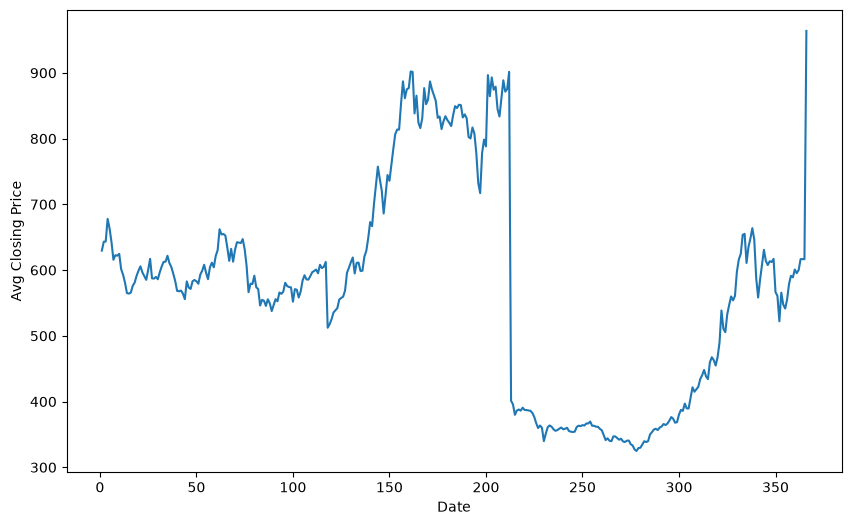

In [23]:
plt.figure(figsize=(10,6))
data.groupby(days)['Close'].mean().plot()
plt.ylabel('Avg Closing Price')

In [24]:
data2.index.quarter

Index([3, 3, 3, 3, 3, 3, 3, 3, 3, 3,
       ...
       2, 2, 2, 2, 2, 2, 2, 2, 2, 2],
      dtype='int32', name='Date', length=1556)

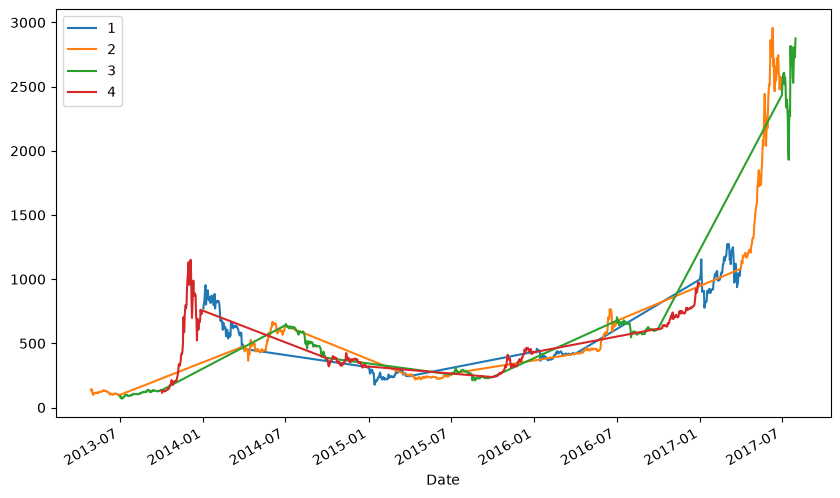

In [25]:
plt.figure(figsize=(10,6))
data.groupby(data2.index.quarter)['Close'].plot()
plt.legend()

In [26]:
data['dayofweek'] = data.index.dayofweek
data.head()

,Open,High,Low,Close,Volume,Market Cap,dayofweek
Date,,,,,,,
2017-07-31,2763.24,2889.62,2720.61,2875.34,"860,575,000","45,535,800,000",0
2017-07-30,2724.39,2758.53,2644.85,2757.18,"705,943,000","44,890,700,000",6
2017-07-29,2807.02,2808.76,2692.80,2726.45,"803,746,000","46,246,700,000",5
2017-07-28,2679.73,2897.45,2679.73,2809.01,"1,380,100,000","44,144,400,000",4
2017-07-27,2538.71,2693.32,2529.34,2671.78,"789,104,000","41,816,500,000",3


In [27]:
def assign_labels(feature):
    if feature<5:
        return 'weekdays'
    else:
        return 'weekends'
data['dayofweek'] = data['dayofweek'].apply(assign_labels)
data.head()

,Open,High,Low,Close,Volume,Market Cap,dayofweek
Date,,,,,,,
2017-07-31,2763.24,2889.62,2720.61,2875.34,"860,575,000","45,535,800,000",weekdays
2017-07-30,2724.39,2758.53,2644.85,2757.18,"705,943,000","44,890,700,000",weekends
2017-07-29,2807.02,2808.76,2692.80,2726.45,"803,746,000","46,246,700,000",weekends
2017-07-28,2679.73,2897.45,2679.73,2809.01,"1,380,100,000","44,144,400,000",weekdays
2017-07-27,2538.71,2693.32,2529.34,2671.78,"789,104,000","41,816,500,000",weekdays


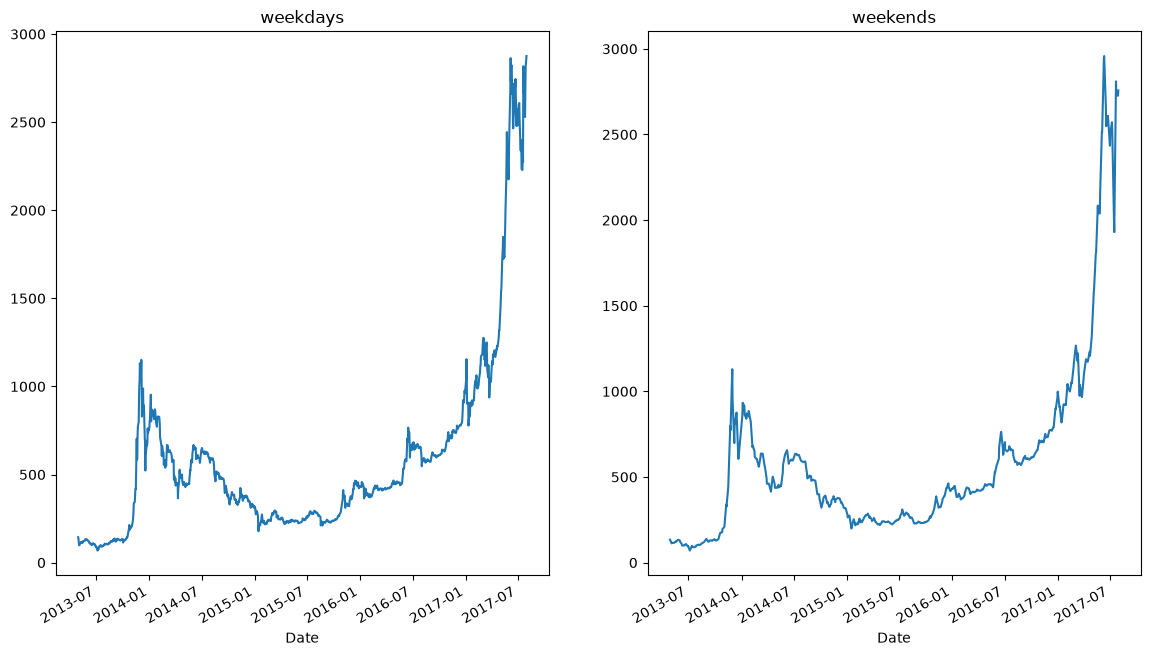

In [28]:
fig,ax = plt.subplots(nrows=1,ncols=2,figsize=(14,8))
data[data['dayofweek']=='weekdays']['Close'].plot(ax=ax[0],title='weekdays')
data[data['dayofweek']=='weekends']['Close'].plot(ax=ax[1],title='weekends')
plt.show()

In [29]:
data['Close']

Date
2017-07-31    2875.34
2017-07-30    2757.18
2017-07-29    2726.45
2017-07-28    2809.01
2017-07-27    2671.78
               ...   
2013-05-02     105.21
2013-05-01     116.99
2013-04-30     139.00
2013-04-29     144.54
2013-04-28     134.21
Name: Close, Length: 1556, dtype: float64

In [30]:
data['Close'].shift(1)

Date
2017-07-31        NaN
2017-07-30    2875.34
2017-07-29    2757.18
2017-07-28    2726.45
2017-07-27    2809.01
               ...   
2013-05-02      97.75
2013-05-01     105.21
2013-04-30     116.99
2013-04-29     139.00
2013-04-28     144.54
Name: Close, Length: 1556, dtype: float64

In [31]:
data['prediction_naive'] = data['Close'].shift(1)
data.head()

,Open,High,Low,Close,Volume,Market Cap,dayofweek,prediction_naive
Date,,,,,,,,
2017-07-31,2763.24,2889.62,2720.61,2875.34,"860,575,000","45,535,800,000",weekdays,NaN
2017-07-30,2724.39,2758.53,2644.85,2757.18,"705,943,000","44,890,700,000",weekends,2875.34
2017-07-29,2807.02,2808.76,2692.80,2726.45,"803,746,000","46,246,700,000",weekends,2757.18
2017-07-28,2679.73,2897.45,2679.73,2809.01,"1,380,100,000","44,144,400,000",weekdays,2726.45
2017-07-27,2538.71,2693.32,2529.34,2671.78,"789,104,000","41,816,500,000",weekdays,2809.01


<Axes: xlabel='Date'>

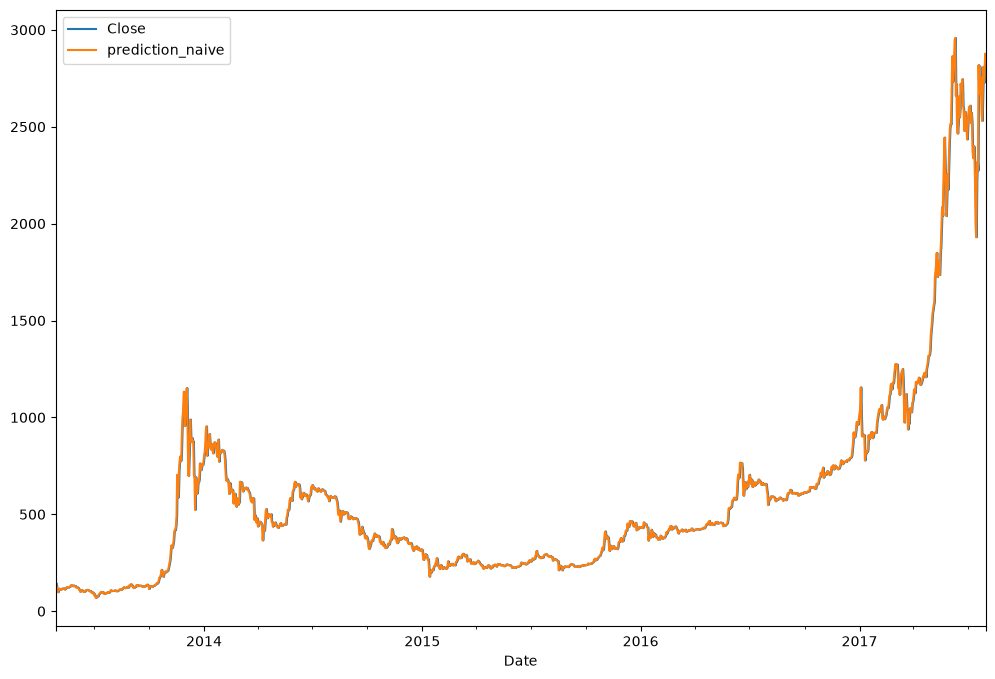

In [32]:
data[['Close','prediction_naive']].plot(figsize=(12,8))

In [33]:
from sklearn.metrics import mean_squared_error
mse = mean_squared_error(data['Close'][1:],data['prediction_naive'][1:])
print('MSE:',mse)

MSE: 1386.3434001929265


In [34]:
np.sqrt(mse)

np.float64(37.23363264835875)

<Axes: xlabel='Date'>

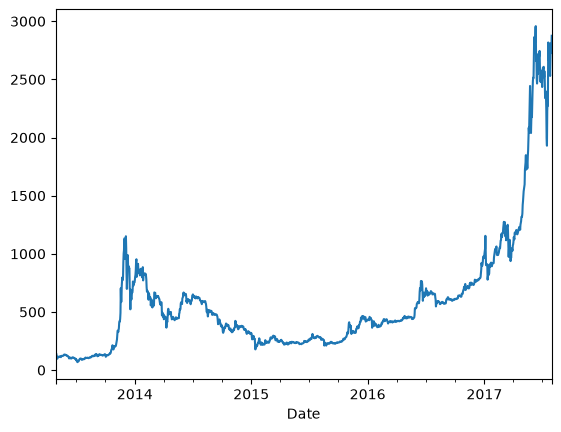

In [35]:
data['Close'].plot()

In [36]:
mean = data['Close'].rolling(window=7).mean()
std = data['Close'].rolling(window=7).std()

In [37]:
mean.head(20)

Date
2017-07-31            NaN
2017-07-30            NaN
2017-07-29            NaN
2017-07-28            NaN
2017-07-27            NaN
2017-07-26            NaN
2017-07-25    2706.527143
2017-07-24    2689.315714
2017-07-23    2685.490000
2017-07-22    2697.442857
2017-07-21    2677.264286
2017-07-20    2698.095714
2017-07-19    2661.521429
2017-07-18    2624.721429
2017-07-17    2549.514286
2017-07-16    2435.145714
2017-07-15    2319.251429
2017-07-14    2257.191429
2017-07-13    2191.520000
2017-07-12    2209.435714
Name: Close, dtype: float64

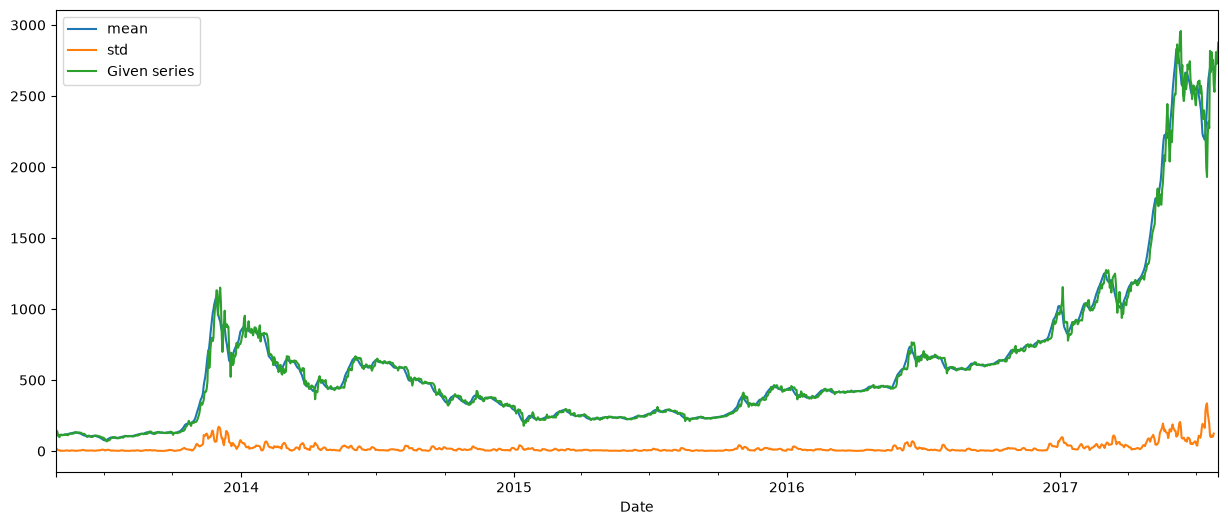

In [38]:
plt.figure(figsize=(15,6))
mean.plot(label='mean')
std.plot(label='std')
data['Close'].plot(label='Given series')
plt.legend()
plt.show()

In [39]:
data['Close'].isnull().sum()

np.int64(0)

In [40]:
from statsmodels.tsa.stattools import adfuller
result = adfuller(data['Close'])
labels = ['ADF Test Statistic','p-value','#Lags Used','#Observations used']
for value,label in zip(result,labels):
    print(label + ': ' + str(value))
if result[1] <= 0.05:
    print("strong evidence against the null hypothesis, reject the null hypothesis. Data has no unit root and is stationary")
else:
    print("weak evidence against the null hypothesis, time series has a unit root, indicating it is non-stationary ")
print('ADF Statistic: %f' % result[0])
print('p-value: %f' % result[1])

ADF Test Statistic: -4.477989431941971
p-value: 0.0002154535155876208
#Lags Used: 24
#Observations used: 1531
strong evidence against the null hypothesis, reject the null hypothesis. Data has no unit root and is stationary
ADF Statistic: -4.477989
p-value: 0.000215


/var/folders/8t/4ttt_tc53hs994xcrmjg2p880000gn/T/ipykernel_36087/2971192010.py:2: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  result = adfuller(data['Close'])


In [41]:
def test_for_stationarity(feature):
    mean = data[feature].rolling(window=24).mean()
    std = data[feature].rolling(window=24).std()

    plt.figure(figsize=(15,6))
    mean.plot(label='mean')
    std.plot(label='std')
    data[feature].plot(label='Given Series')
    plt.legend()
    result = adfuller(data[feature].dropna())
    labels = ['ADF Test Statistic','p-value','#Lags Used','#Observations used']
    for value,label in zip(result,labels):
        print(label + ': ' + str(value))
    if result[1] <= 0.05:
        print("strong evidence against the null hypothesis, reject the null hypothesis. Data has no unit root and is stationary")
    else:
        print("weak evidence against the null hypothesis, time series has a unit root, indicating it is non-stationary ")
    print('ADF Statistic: %f' % result[0])
    print('p-value: %f' % result[1])
    plt.show()

ADF Test Statistic: -4.477989431941971
p-value: 0.0002154535155876208
#Lags Used: 24
#Observations used: 1531
strong evidence against the null hypothesis, reject the null hypothesis. Data has no unit root and is stationary
ADF Statistic: -4.477989
p-value: 0.000215


/var/folders/8t/4ttt_tc53hs994xcrmjg2p880000gn/T/ipykernel_36087/1197822845.py:10: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  result = adfuller(data[feature].dropna())


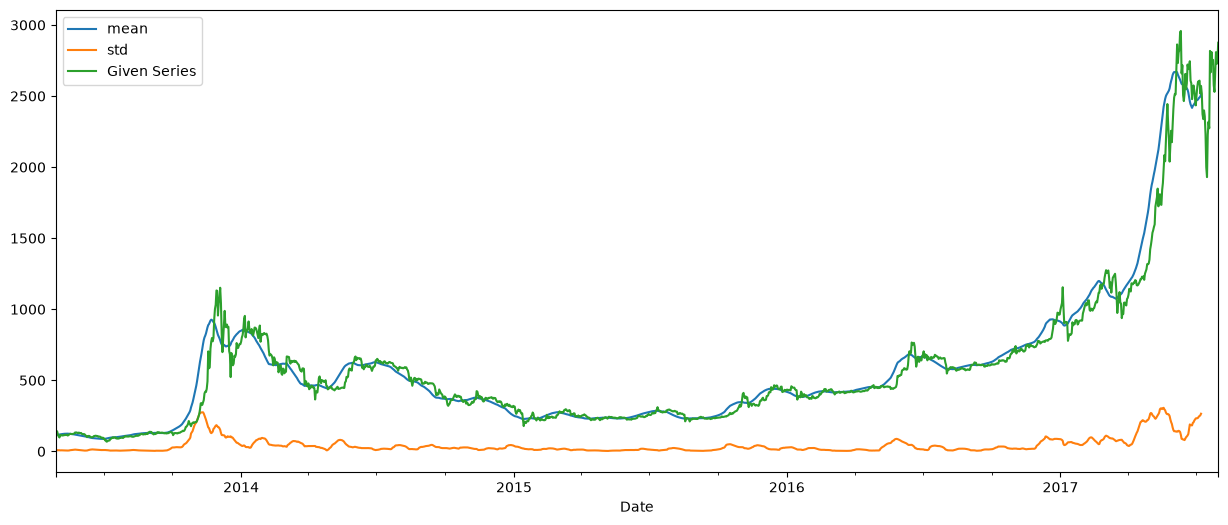

In [42]:
test_for_stationarity('Close')

In [43]:
log_data = np.log(data['Close'])

<Axes: xlabel='Date'>

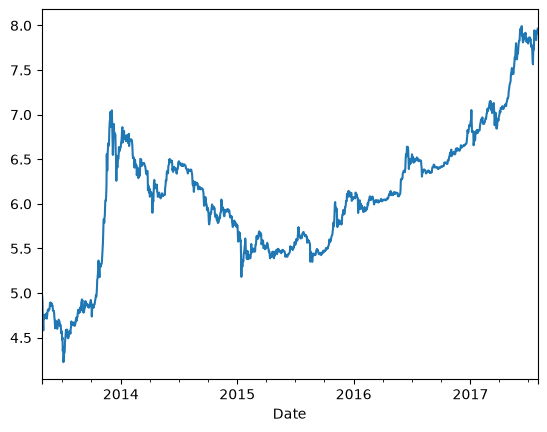

In [44]:
np.log(data['Close']).plot()

In [45]:
rolling_avg = log_data - log_data.shift(7)
rolling_avg

Date
2017-07-31         NaN
2017-07-30         NaN
2017-07-29         NaN
2017-07-28         NaN
2017-07-27         NaN
                ...   
2013-05-02   -0.068505
2013-05-01    0.029669
2013-04-30    0.220449
2013-04-29    0.252382
2013-04-28    0.146592
Name: Close, Length: 1556, dtype: float64

In [46]:
Rolling_average = log_data.rolling(window=7).mean()

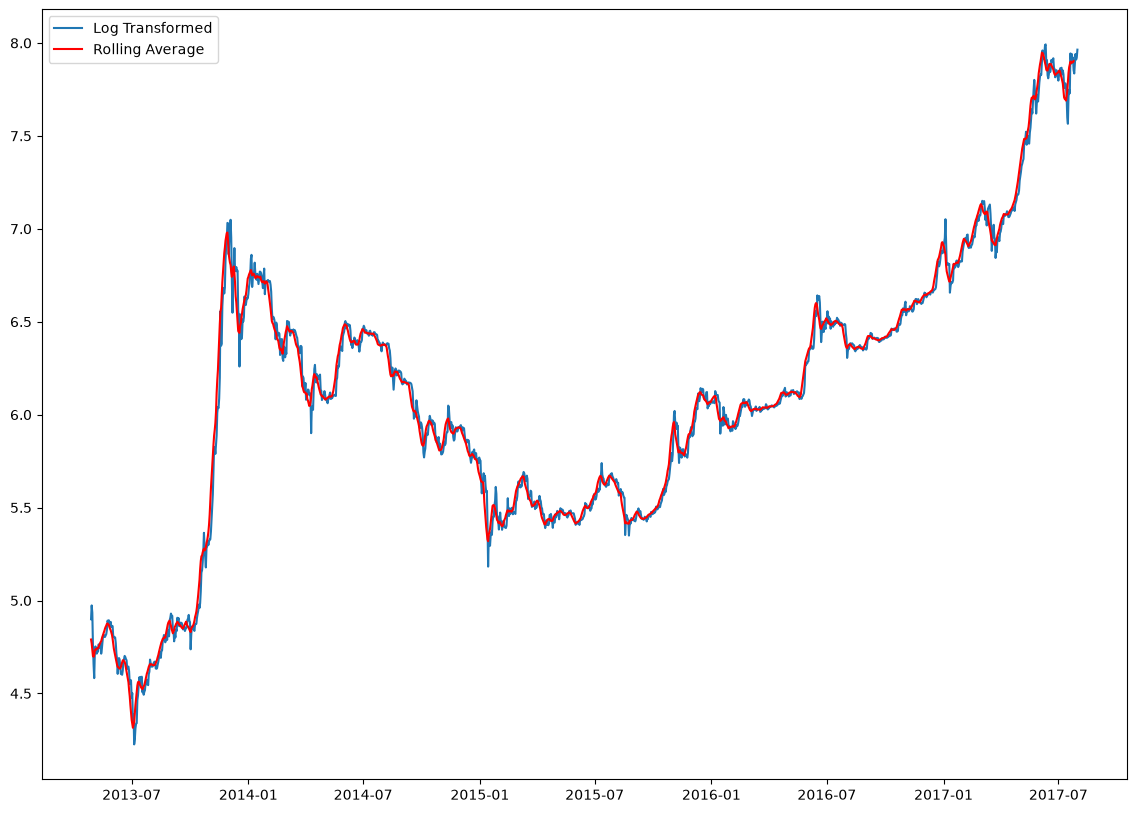

In [47]:
plt.figure(figsize=(14,10))
plt.plot(log_data, label='Log Transformed')
plt.plot(Rolling_average, color='red', label='Rolling Average')
plt.legend(loc='best')
plt.show()

In [48]:
lr_diff = log_data - Rolling_average
lr_diff

Date
2017-07-31         NaN
2017-07-30         NaN
2017-07-29         NaN
2017-07-28         NaN
2017-07-27         NaN
                ...   
2013-05-02   -0.041435
2013-05-01    0.060456
2013-04-30    0.201349
2013-04-29    0.204377
2013-04-28    0.109284
Name: Close, Length: 1556, dtype: float64

In [49]:
data['lr_diff'] = lr_diff

ADF Test Statistic: -7.188887202324551
p-value: 2.5340955586100546e-10
#Lags Used: 22
#Observations used: 1527
strong evidence against the null hypothesis, reject the null hypothesis. Data has no unit root and is stationary
ADF Statistic: -7.188887
p-value: 0.000000


/var/folders/8t/4ttt_tc53hs994xcrmjg2p880000gn/T/ipykernel_36087/1197822845.py:10: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  result = adfuller(data[feature].dropna())


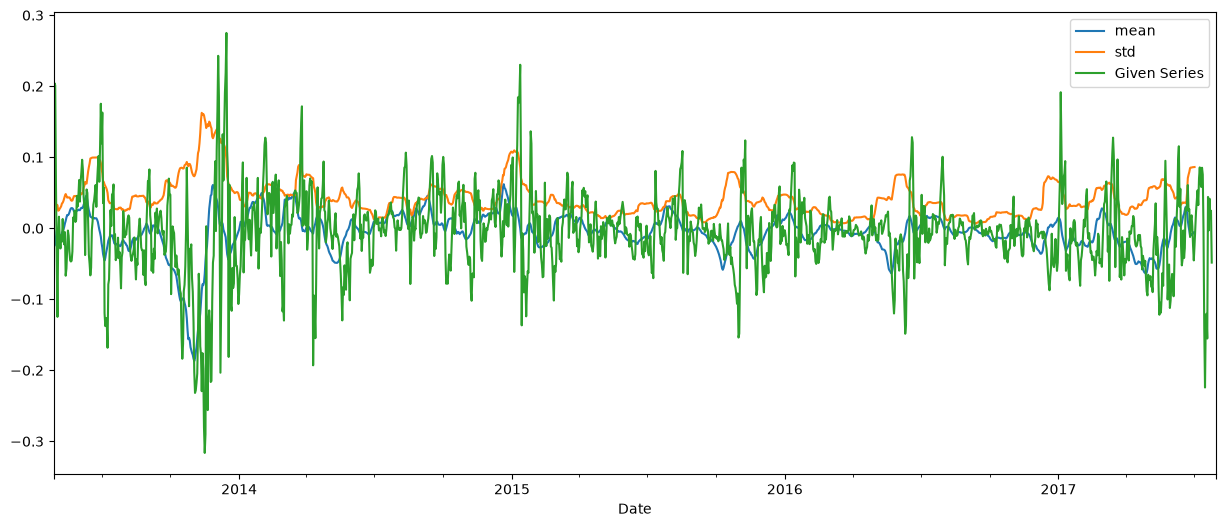

In [50]:
test_for_stationarity('lr_diff')

In [51]:
log_ts = log_data - log_data.shift(7)
log_ts

Date
2017-07-31         NaN
2017-07-30         NaN
2017-07-29         NaN
2017-07-28         NaN
2017-07-27         NaN
                ...   
2013-05-02   -0.068505
2013-05-01    0.029669
2013-04-30    0.220449
2013-04-29    0.252382
2013-04-28    0.146592
Name: Close, Length: 1556, dtype: float64

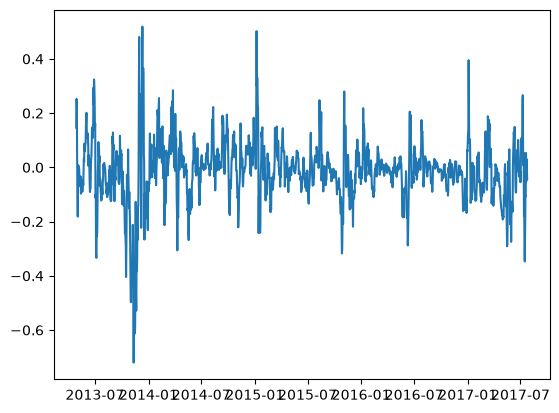

In [52]:
plt.plot(log_ts)

In [53]:
data['log_ts'] = log_ts

ADF Test Statistic: -6.51172259631673
p-value: 1.0961860829579598e-08
#Lags Used: 23
#Observations used: 1525
strong evidence against the null hypothesis, reject the null hypothesis. Data has no unit root and is stationary
ADF Statistic: -6.511723
p-value: 0.000000


/var/folders/8t/4ttt_tc53hs994xcrmjg2p880000gn/T/ipykernel_36087/1197822845.py:10: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  result = adfuller(data[feature].dropna())


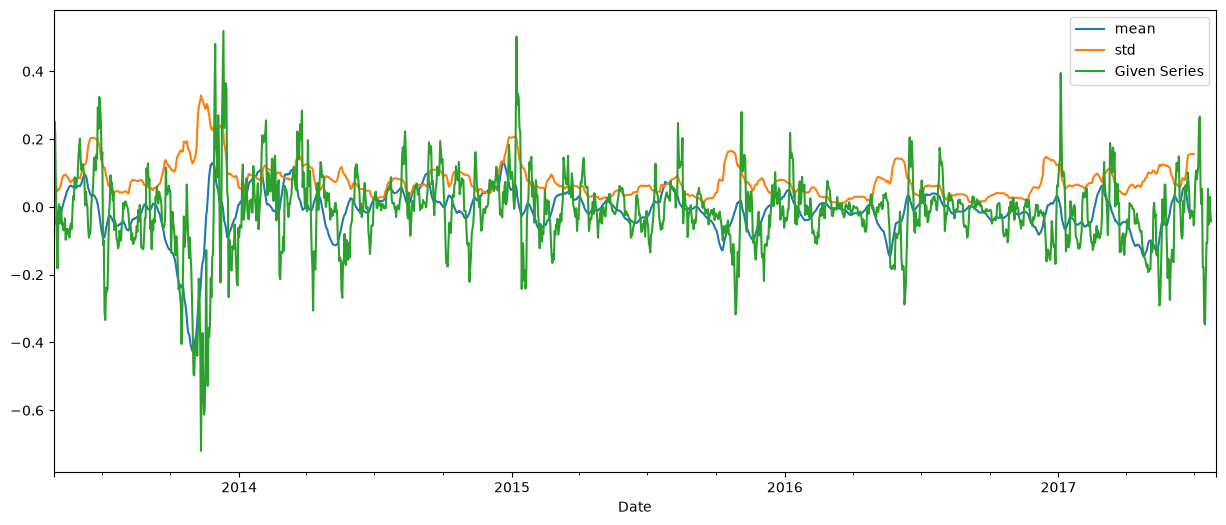

In [54]:
test_for_stationarity('log_ts')

In [55]:
from prophet import Prophet

Importing plotly failed. Interactive plots will not work.


In [56]:
model = Prophet()

/Users/ankit/Workspace/Projects/ankit-github/AI-ML-DS/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [57]:
df = data[['Close']]

In [58]:
df.head()

,Close
Date,
2017-07-31,2875.34
2017-07-30,2757.18
2017-07-29,2726.45
2017-07-28,2809.01
2017-07-27,2671.78


In [59]:
df= df.reset_index()
df.columns = ['ds', 'y']
df.head()

,ds,y
0,2017-07-31,2875.34
1,2017-07-30,2757.18
2,2017-07-29,2726.45
3,2017-07-28,2809.01
4,2017-07-27,2671.78


In [60]:
m=model.fit(df)

01:50:06 - cmdstanpy - INFO - Chain [1] start processing
01:50:06 - cmdstanpy - INFO - Chain [1] done processing


In [62]:
future = m.make_future_dataframe(periods=500,freq='D')
future.head()

,ds
0,2013-04-28
1,2013-04-29
2,2013-04-30
3,2013-05-01
4,2013-05-02


In [64]:
data.shape

(1556, 10)

In [65]:
future.shape

(2056, 1)

In [ ]:
forecast = m.predict(future)
forecast[['ds', 'yhat', 'yhat_lower', 'yhat_upper']].tail()